<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-02/homework2.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Tarea 2: Neural Networks Driven by Physics and CNNs for RGB Demosaicking

**Fotografia Computacional**  
**Universidad Tecnica Federico Santa Maria**

En esta tarea se estudia el problema de reconstruccion de imagenes RGB a partir de mediciones con mosaico Bayer obtenidas desde sensores reales. En particular, se busca comparar metodos clasicos de demosaicking con aproximaciones basadas en redes neuronales, incluyendo representaciones neuronales implicitas y redes convolucionales.


## 1. Enunciado

El objetivo general de la tarea es reconstruir una imagen RGB a partir de una medicion mosaico capturada por un dispositivo electronico, como un telefono, tablet o camara digital. La medicion corresponde a una imagen RAW o DNG generada por un sensor cubierto con un arreglo de filtros de color Bayer.

A partir de esta medicion, se deben implementar y analizar algoritmos de demosaicking basados en:

1. Metodos tradicionales de interpolacion.
2. Representaciones neuronales implicitas.
3. Redes neuronales convolucionales.

Los resultados deben compararse cuantitativa y cualitativamente con una imagen RGB de referencia, por ejemplo la imagen procesada automaticamente por el dispositivo.


## 2. Contexto teorico

Una camara digital usualmente no mide directamente los tres canales de color en cada pixel. En su lugar, el sensor registra una unica intensidad por posicion espacial, filtrada por un patron Bayer. Para un patron Bayer tipo **RGGB**, la distribucion local de filtros puede representarse como

$$
\begin{bmatrix}
R & G \\
G & B
\end{bmatrix}.
$$

Sea

$$
I \in \mathbb{R}^{H \times W \times 3}
$$

la imagen RGB ideal, donde $H$ y $W$ son la altura y el ancho de la imagen. La medicion mosaico puede modelarse como

$$
Y(i,j) = \sum_{c \in \{R,G,B\}} M_c(i,j) I_c(i,j),
$$

donde $M_c$ es una mascara binaria que indica si el canal $c$ fue medido en la posicion $(i,j)$.

El problema de **demosaicking** consiste en estimar una imagen RGB completa

$$
\hat{I} \in \mathbb{R}^{H \times W \times 3}
$$

a partir de la medicion incompleta $Y$.


## 3. Objetivos

Los objetivos especificos de esta tarea son:

1. Obtener o utilizar una imagen RAW/DNG junto con una imagen RGB de referencia.
2. Representar la medicion del sensor como un mosaico Bayer.
3. Reconstruir la imagen RGB usando un metodo clasico de demosaicking.
4. Reconstruir la imagen RGB usando una representacion neuronal implicita.
5. Reconstruir la imagen RGB usando una red neuronal convolucional.
6. Comparar los metodos mediante metricas objetivas y observaciones visuales.
7. Analizar el efecto de modificar la arquitectura o estrategia de entrenamiento de las redes.


## 4. Preparacion del entorno

En esta seccion se cargaran las librerias necesarias para trabajar con imagenes, arreglos numericos, visualizacion, metricas y entrenamiento de redes neuronales.

Las implementaciones finales deberian considerar, al menos:

- `numpy` para operaciones numericas.
- `matplotlib` para visualizacion.
- `Pillow` u `OpenCV` para lectura y procesamiento de imagenes.
- `torch` para definir y entrenar redes neuronales.
- `pandas` para organizar los resultados experimentales.


In [1]:
# Dependencias para Google Colab
# En Colab, torch suele venir instalado. Esta celda asegura el resto de paquetes usados en la tarea.
%pip install -q opencv-python scikit-image scipy pillow pandas matplotlib rawpy imageio

# Imports generales
from pathlib import Path
from collections import OrderedDict
import os
import time
import math
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2
from skimage import data
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import correlate

try:
    import rawpy
except ImportError:
    rawpy = None

import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 91.1 MB/s eta 0:00:00
Device: cuda


## 5. Datos de trabajo

Para que la respuesta no dependa de entrenar con una unica imagen, se separan dos usos de datos:

1. **Imagen controlada (`astronaut`)**: se usa para validar el pipeline completo, porque se conoce la referencia RGB exacta y se puede crear un mosaico Bayer sintetico.
2. **Dataset Kodak**: se usa para entrenar y evaluar la CNN con varias imagenes. La separacion entrenamiento/prueba se hace por imagen completa antes de crear parches, evitando fuga de informacion entre conjuntos.

La parte con captura real RAW/DNG queda pendiente, porque los archivos disponibles para esta entrega estan corruptos o no se pueden leer de forma confiable. Por lo tanto, las conclusiones se basan en el experimento controlado y en la evaluacion multi-imagen con Kodak.

Con esta organizacion, la SIREN se interpreta como un metodo optimizado por imagen a partir de la medicion, mientras que la CNN se interpreta como un modelo supervisado que debe generalizar a imagenes no vistas.


### Pendiente: captura real RAW/DNG

La seccion de carga de `bursts_0006.dng`, `bursts_0006.tiff` y `bursts_0006.jpg` se deja pendiente porque los archivos disponibles estan corruptos. Cuando se cuente con una captura valida, se puede agregar aqui la lectura del RAW, la deteccion del patron Bayer y la comparacion cualitativa contra una referencia JPG/TIFF procesada por la camara.


## 6. Experimento controlado con `skimage.data.astronaut`

Siguiendo el notebook base `homework2a.ipynb`, se usara la imagen `astronaut` como referencia RGB inicial. Esta eleccion tiene dos ventajas:

1. La imagen viene incluida en `scikit-image`, por lo que el experimento es reproducible en Colab.
2. Al conocer la imagen RGB original, se puede generar un mosaico Bayer sintetico y evaluar las reconstrucciones con metricas objetivas.

En este caso,

$$
I_{\text{ref}} = I_{\text{astronaut}}.
$$

A partir de esta imagen se construira el mosaico $Y$ usando el patron Bayer RGGB.

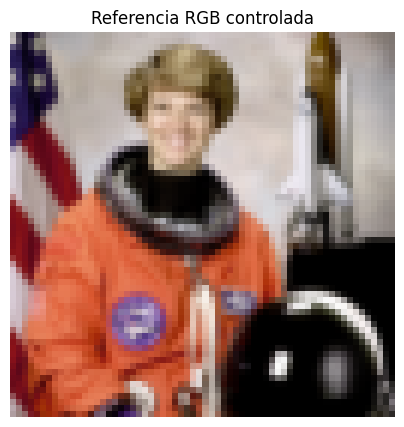

In [2]:
# Carga de imagen controlada: astronaut
N = 64
rgb_reference = data.astronaut()
rgb_reference = resize(rgb_reference, (N, N), anti_aliasing=True).astype(np.float32)
if rgb_reference.max() > 1:
    rgb_reference = rgb_reference / 255.0

plt.figure(figsize=(5, 5))
plt.imshow(rgb_reference)
plt.title("Referencia RGB controlada")
plt.axis("off");


## 7. Modelo de mosaico Bayer

Para un patron Bayer RGGB, se definen tres mascaras binarias:

$$
M_R, M_G, M_B \in \{0,1\}^{H \times W}.
$$

Cada mascara indica las posiciones del sensor donde se mide cada canal. La medicion mosaico puede escribirse como

$$
Y = M_R \odot I_R + M_G \odot I_G + M_B \odot I_B,
$$

donde $\odot$ representa el producto elemento a elemento.

Esta seccion debe construir o leer la medicion $Y$ y visualizar el patron de muestreo utilizado.


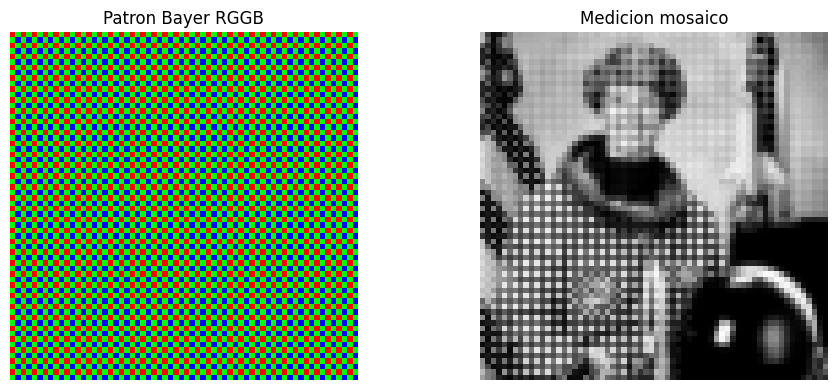

In [3]:
# Mascaras Bayer y medicion mosaico
def bayer_masks(height, width, pattern="RGGB"):
    """Construye mascaras binarias RGB para un patron Bayer de 2x2."""
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

def make_bayer_mosaic(rgb_image, masks):
    return np.sum(rgb_image * masks, axis=-1).astype(np.float32)

bayer_pattern = "RGGB"
bayer = bayer_masks(*rgb_reference.shape[:2], pattern=bayer_pattern)
mosaic = make_bayer_mosaic(rgb_reference, bayer)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(bayer)
axes[0].set_title(f"Patron Bayer {bayer_pattern}")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Medicion mosaico")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 8. Metodo clasico de demosaicking

Como linea base, se debe reconstruir la imagen RGB usando un metodo tradicional. Un enfoque simple consiste en interpolar los valores faltantes de cada canal a partir de las muestras disponibles.

La reconstruccion clasica se denotara como

$$
\hat{I}_{\text{clasico}}.
$$

Esta reconstruccion servira como referencia inicial para evaluar si los metodos neuronales entregan mejoras cuantitativas o visuales.


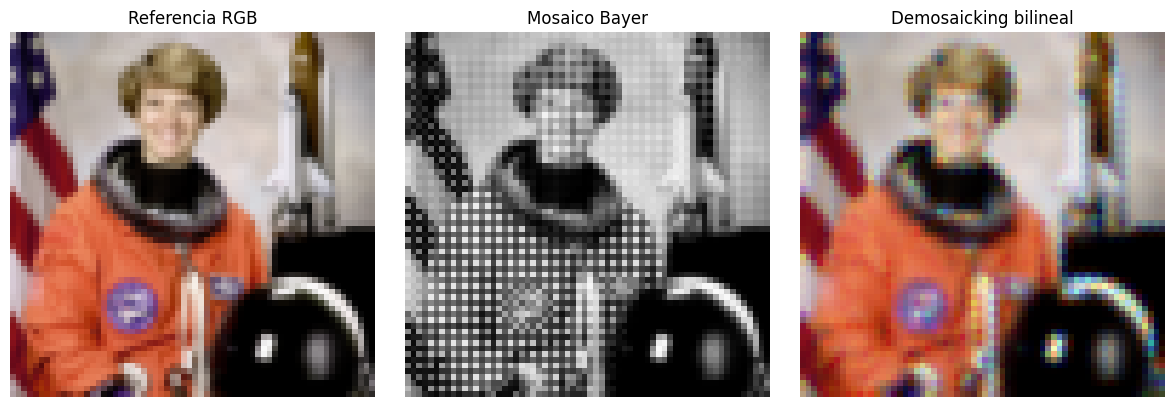

In [4]:
# Demosaicking clasico por interpolacion bilineal
def demosaic_bilinear(mosaic, masks):
    # Los kernels separables estiman los valores faltantes de cada canal.
    kernels = [
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
        np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=np.float32),
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
    ]
    channels = []
    for channel, kernel in enumerate(kernels):
        observed = mosaic * masks[..., channel]
        estimate = correlate(observed, kernel, mode="mirror") / 4.0
        # Conserva exactamente las muestras que el sensor si observo.
        channels.append(np.where(masks[..., channel] > 0, observed, estimate))
    return np.clip(np.stack(channels, axis=-1), 0.0, 1.0).astype(np.float32)

I_hat_classic = demosaic_bilinear(mosaic, bayer)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_classic)
axes[2].set_title("Demosaicking bilineal")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 9. Representacion neuronal implicita

Una representacion neuronal implicita modela una senal como una funcion continua parametrizada por una red neuronal. En este caso, se busca aprender una funcion

$$
f_\theta: \mathbb{R}^3 \rightarrow \mathbb{R},
$$

donde la entrada corresponde a una coordenada espacial y un indice de canal,

$$
(x, y, c),
$$

y la salida corresponde a una intensidad estimada.

El entrenamiento utiliza solamente las posiciones observadas en el mosaico Bayer. La funcion de perdida puede escribirse como

$$
\mathcal{L}(\theta) = \frac{1}{|\Omega|} \sum_{(i,j,c) \in \Omega}
\left( f_\theta(x_i, y_j, c) - Y(i,j) \right)^2,
$$

donde $\Omega$ es el conjunto de muestras disponibles en el sensor.

La reconstruccion obtenida se denotara por

$$
\hat{I}_{\text{INR}}.
$$


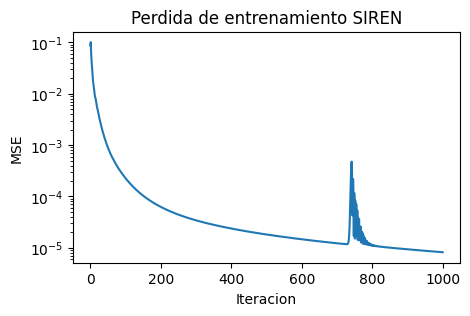

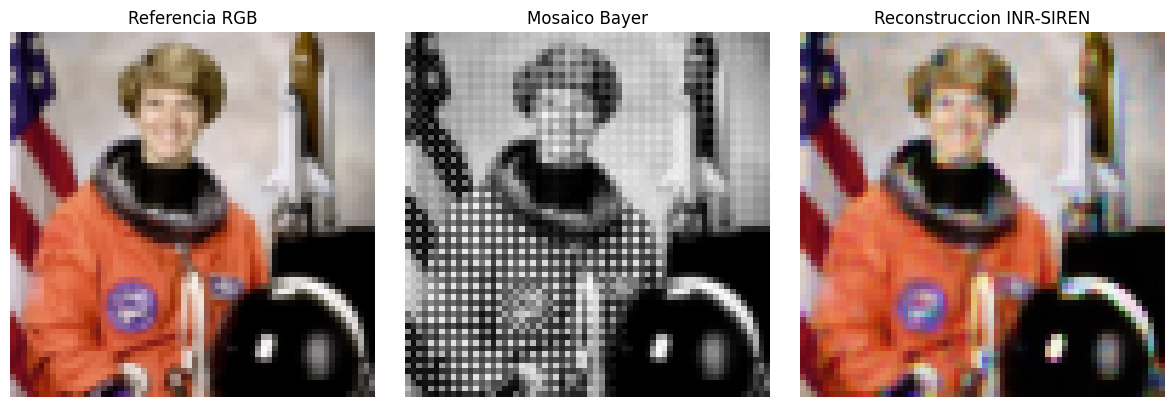

In [5]:
# Representacion neuronal implicita tipo SIREN
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0=30.0, is_first=False):
        super().__init__()
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        with torch.no_grad():
            if is_first:
                self.linear.weight.uniform_(-1 / in_features, 1 / in_features)
            else:
                bound = np.sqrt(6 / in_features) / omega_0
                self.linear.weight.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))

class Siren(nn.Module):
    def __init__(self, hidden_features=256, hidden_layers=3, out_features=3):
        super().__init__()
        layers = [SineLayer(2, hidden_features, is_first=True)]
        layers += [SineLayer(hidden_features, hidden_features) for _ in range(hidden_layers)]
        layers += [nn.Linear(hidden_features, out_features)]
        self.net = nn.Sequential(*layers)

    def forward(self, coords):
        return torch.sigmoid(self.net(coords))

def build_spatial_grid(height, width):
    yy, xx = np.meshgrid(
        np.linspace(-1, 1, height, dtype=np.float32),
        np.linspace(-1, 1, width, dtype=np.float32),
        indexing="ij",
    )
    coords = np.stack([xx.ravel(), yy.ravel()], axis=1)
    return torch.from_numpy(coords).float()

def train_siren_from_mosaic(mosaic, masks, hidden_features=256, hidden_layers=3, steps=1000, learning_rate=1e-4):
    height, width = mosaic.shape
    coords = build_spatial_grid(height, width).to(DEVICE)
    mosaic_tensor = torch.from_numpy(mosaic[..., None]).float().to(DEVICE)
    masks_tensor = torch.from_numpy(masks).float().to(DEVICE)
    model = Siren(hidden_features, hidden_layers, out_features=3).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    model.train()
    for step in range(steps):
        rgb_prediction = model(coords).reshape(height, width, 3)
        mosaic_prediction = torch.sum(rgb_prediction * masks_tensor, dim=-1, keepdim=True)
        loss = F.mse_loss(mosaic_prediction, mosaic_tensor)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())

    model.eval()
    with torch.no_grad():
        reconstruction = model(coords).reshape(height, width, 3).cpu().numpy()
    return model, np.clip(reconstruction, 0.0, 1.0).astype(np.float32), history

model_inr, I_hat_inr, loss_history = train_siren_from_mosaic(
    mosaic, bayer, hidden_features=256, hidden_layers=3, steps=1000
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.yscale("log")
plt.title("Perdida de entrenamiento SIREN")
plt.xlabel("Iteracion")
plt.ylabel("MSE")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_inr)
axes[2].set_title("Reconstruccion INR-SIREN")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. Red neuronal convolucional

El segundo enfoque neuronal consiste en entrenar una red convolucional que reciba como entrada la medicion mosaico y produzca directamente una imagen RGB.

La entrada se define como

$$
X_{\text{CNN}} = [Y, M_R, M_G, M_B] \in \mathbb{R}^{H \times W \times 4}.
$$

La CNN aprende una funcion

$$
g_\phi: \mathbb{R}^{H \times W \times 4} \rightarrow \mathbb{R}^{H \times W \times 3}.
$$

Primero se entrena una version pequena con `astronaut` para verificar que el codigo funciona. Esa prueba no se usa como evidencia de generalizacion. La evaluacion principal de la CNN se realiza despues con Kodak, entrenando con varias imagenes y midiendo el desempeno sobre imagenes no vistas.


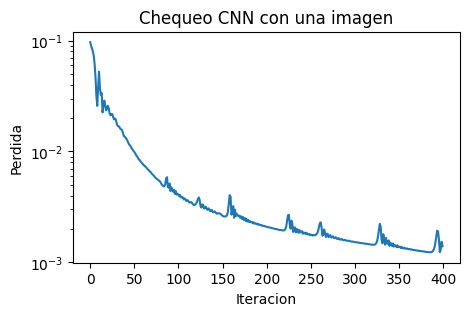

In [6]:
# Red neuronal convolucional
def build_cnn_input(mosaic, masks):
    """Construye X_CNN = [Y, M_R, M_G, M_B] con formato NCHW."""
    input_image = np.concatenate([mosaic[..., None], masks], axis=-1)
    return torch.from_numpy(input_image.transpose(2, 0, 1)[None]).float()

class ResidualBlock(nn.Module):
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
        )

    def forward(self, x):
        return x + self.block(x)

class DemosaicCNN(nn.Module):
    def __init__(self, input_channels=4, hidden_channels=32, num_blocks=4):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Conv2d(input_channels, hidden_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.residual_layers = nn.Sequential(
            *[ResidualBlock(hidden_channels) for _ in range(num_blocks)]
        )
        self.output_layer = nn.Conv2d(hidden_channels, 3, 3, padding=1)

    def forward(self, x):
        features = self.input_layer(x)
        features = self.residual_layers(features)
        return torch.sigmoid(self.output_layer(features))

def sensor_consistency_loss(prediction, input_tensor):
    """Penaliza que la reconstruccion reproduzca la medicion Bayer observada."""
    mosaic_reprojected = torch.sum(prediction * input_tensor[:, 1:4], dim=1, keepdim=True)
    return F.mse_loss(mosaic_reprojected, input_tensor[:, 0:1])

def train_cnn_single_image(model, input_tensor, target_tensor, steps=400, learning_rate=1e-3, physics_weight=0.1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for step in range(steps):
        prediction = model(input_tensor)
        rgb_loss = F.mse_loss(prediction, target_tensor)
        physics_loss = sensor_consistency_loss(prediction, input_tensor)
        loss = rgb_loss + physics_weight * physics_loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return history

cnn_input = build_cnn_input(mosaic, bayer).to(DEVICE)
cnn_target = torch.from_numpy(rgb_reference.transpose(2, 0, 1)[None]).float().to(DEVICE)
model_cnn_single = DemosaicCNN(input_channels=4, hidden_channels=32, num_blocks=4).to(DEVICE)
cnn_single_history = train_cnn_single_image(model_cnn_single, cnn_input, cnn_target, steps=400)

model_cnn_single.eval()
with torch.no_grad():
    cnn_output = model_cnn_single(cnn_input)[0].cpu().numpy()
I_hat_cnn_single = cnn_output.transpose(1, 2, 0).astype(np.float32)

plt.figure(figsize=(5, 3))
plt.plot(cnn_single_history)
plt.yscale("log")
plt.title("Chequeo CNN con una imagen")
plt.xlabel("Iteracion")
plt.ylabel("Perdida")
plt.show()


## 10.1. Entrenamiento de la CNN con varias imagenes

El entrenamiento con una sola imagen solo verifica el pipeline. Para evaluar generalizacion se usa el dataset Kodak, siguiendo la idea del notebook `extra/cnnDemosaicing.ipynb`.

La division se hace de esta forma:

- 20 imagenes Kodak para entrenamiento.
- 4 imagenes Kodak para prueba.
- Cada imagen se divide en parches de 64 x 64.
- Los parches de prueba provienen de imagenes completas que no fueron usadas durante el entrenamiento.

Asi, cuando se reportan metricas de la CNN sobre Kodak, esas metricas corresponden a imagenes no vistas por el modelo.


Imagenes de entrenamiento: 20
Imagenes de prueba: 4
Parches de entrenamiento: 1920
Parches de prueba: 384
Epoca 01/6: perdida = 0.017660
Epoca 02/6: perdida = 0.006288
Epoca 03/6: perdida = 0.002813
Epoca 04/6: perdida = 0.002146
Epoca 05/6: perdida = 0.001502
Epoca 06/6: perdida = 0.001077
MSE promedio en parches de prueba Kodak: 0.000839


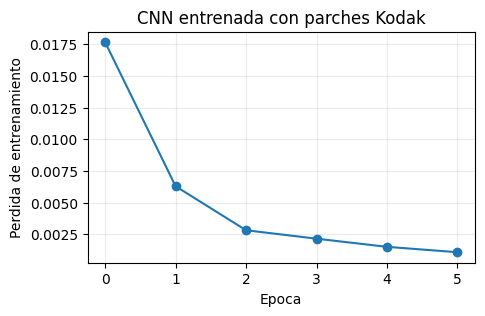

In [7]:
# Dataset Kodak para entrenamiento supervisado multi-imagen
# Rutas para ejecucion local o Colab
try:
    from google.colab import files  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "tareas" / "tarea-02").exists() and Path.cwd().name == "tarea-02":
    REPO_ROOT = Path.cwd().parents[1]

TASK_DIR = REPO_ROOT / "tareas" / "tarea-02"
LOCAL_DATASET_DIR = REPO_ROOT / "tareas" / "dataset"
DATA_DIR = Path("/content") if IN_COLAB else TASK_DIR

KODAK_DIR = DATA_DIR / "kodak"
KODAK_DIR.mkdir(exist_ok=True)
KODAK_ZIP = KODAK_DIR / "kodak.zip"
KODAK_URL = "https://arizona.box.com/shared/static/5bk6qar4vgfizmhum8onreu6sp90bz2i"

# El repositorio tambien trae tareas/dataset/01.png ... 24.png; se usa como respaldo local.
def select_local_kodak_paths(dataset_dir):
    if not dataset_dir.exists():
        return []
    selected = []
    for index in range(1, 25):
        candidates = [dataset_dir / f"{index:02d}.png", dataset_dir / f"{index}.png"]
        selected.extend([path for path in candidates if path.exists()][:1])
    return selected

local_kodak_paths = select_local_kodak_paths(LOCAL_DATASET_DIR)
if len(local_kodak_paths) >= 8:
    kodak_paths = local_kodak_paths
else:
    if not list(KODAK_DIR.rglob("kodim*.png")):
        urllib.request.urlretrieve(KODAK_URL, KODAK_ZIP)
        with zipfile.ZipFile(KODAK_ZIP, "r") as zip_ref:
            zip_ref.extractall(KODAK_DIR)
    kodak_paths = sorted(KODAK_DIR.rglob("kodim*.png"))

if len(kodak_paths) < 8:
    raise RuntimeError(f"Se encontraron {len(kodak_paths)} imagenes Kodak; revisa la descarga o tareas/dataset.")

kodak_paths = kodak_paths[:24]
train_paths = kodak_paths[:-4]
test_paths = kodak_paths[-4:]
print(f"Imagenes de entrenamiento: {len(train_paths)}")
print(f"Imagenes de prueba: {len(test_paths)}")

class KodakPatchDataset(Dataset):
    def __init__(self, image_paths, patch_size=64, stride=64, max_patches_per_image=None):
        self.samples = []
        self.patch_size = patch_size
        for path in image_paths:
            image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
            height, width = image.shape[:2]
            image_samples = []
            for top in range(0, height - patch_size + 1, stride):
                for left in range(0, width - patch_size + 1, stride):
                    image_samples.append(image[top:top + patch_size, left:left + patch_size])
            if max_patches_per_image is not None:
                image_samples = image_samples[:max_patches_per_image]
            self.samples.extend(image_samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        rgb = self.samples[index]
        masks = bayer_masks(self.patch_size, self.patch_size, pattern=bayer_pattern)
        mosaic_patch = make_bayer_mosaic(rgb, masks)
        input_patch = np.concatenate([mosaic_patch[..., None], masks], axis=-1)
        input_tensor = torch.from_numpy(input_patch.transpose(2, 0, 1)).float()
        target_tensor = torch.from_numpy(rgb.transpose(2, 0, 1)).float()
        return input_tensor, target_tensor

train_dataset = KodakPatchDataset(train_paths, patch_size=64, stride=64)
test_dataset = KodakPatchDataset(test_paths, patch_size=64, stride=64)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)
print(f"Parches de entrenamiento: {len(train_dataset)}")
print(f"Parches de prueba: {len(test_dataset)}")

def train_cnn_loader(model, loader, epochs=6, learning_rate=1e-3, physics_weight=0.1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            predictions = model(inputs)
            rgb_loss = F.mse_loss(predictions, targets)
            physics_loss = sensor_consistency_loss(predictions, inputs)
            loss = rgb_loss + physics_weight * physics_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * inputs.size(0)
        epoch_loss /= len(loader.dataset)
        history.append(epoch_loss)
        print(f"Epoca {epoch + 1:02d}/{epochs}: perdida = {epoch_loss:.6f}")
    return history

def evaluate_cnn_loader(model, loader):
    model.eval()
    losses = []
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu()
            losses.append(F.mse_loss(predictions, targets).item())
    return float(np.mean(losses))

model_cnn_kodak = DemosaicCNN(input_channels=4, hidden_channels=32, num_blocks=4).to(DEVICE)
kodak_loss_history = train_cnn_loader(model_cnn_kodak, train_loader, epochs=6)
kodak_test_mse = evaluate_cnn_loader(model_cnn_kodak, test_loader)
print(f"MSE promedio en parches de prueba Kodak: {kodak_test_mse:.6f}")

plt.figure(figsize=(5, 3))
plt.plot(kodak_loss_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Perdida de entrenamiento")
plt.title("CNN entrenada con parches Kodak")
plt.grid(alpha=0.25)
plt.show()


## 11. Variantes experimentales

Para estudiar el efecto de la arquitectura se comparan dos CNN entrenadas sobre Kodak:

| Metodo | Canales ocultos | Bloques residuales | Uso |
|---|---:|---:|---|
| CNN pequena | 16 | 2 | Menor costo computacional |
| CNN base | 32 | 4 | Mayor capacidad de reconstruccion |

La comparacion se reporta sobre el conjunto de prueba, es decir, sobre parches provenientes de imagenes no vistas durante entrenamiento.


In [8]:
# Variantes de arquitectura y entrenamiento para la CNN Kodak
cnn_experiments = [
    {"nombre": "CNN pequena", "hidden_channels": 16, "num_blocks": 2, "epochs": 4},
    {"nombre": "CNN base", "hidden_channels": 32, "num_blocks": 4, "epochs": 4},
]

def run_cnn_experiment(config):
    start_time = time.perf_counter()
    model = DemosaicCNN(
        input_channels=4,
        hidden_channels=config["hidden_channels"],
        num_blocks=config["num_blocks"],
    ).to(DEVICE)
    history = train_cnn_loader(model, train_loader, epochs=config["epochs"], physics_weight=0.1)
    test_mse = evaluate_cnn_loader(model, test_loader)
    return {
        "metodo": config["nombre"],
        "canales": config["hidden_channels"],
        "bloques": config["num_blocks"],
        "epocas": config["epochs"],
        "MSE prueba": test_mse,
        "tiempo [s]": time.perf_counter() - start_time,
    }, history

variant_rows = []
variant_histories = {}
for config in cnn_experiments:
    row, history = run_cnn_experiment(config)
    variant_rows.append(row)
    variant_histories[config["nombre"]] = history

variants_df = pd.DataFrame(variant_rows).sort_values("MSE prueba")
display(variants_df.round(4))


Epoca 01/4: perdida = 0.024580
Epoca 02/4: perdida = 0.008757
Epoca 03/4: perdida = 0.007422
Epoca 04/4: perdida = 0.006314
Epoca 01/4: perdida = 0.014182
Epoca 02/4: perdida = 0.005202
Epoca 03/4: perdida = 0.002337
Epoca 04/4: perdida = 0.001556


,metodo,canales,bloques,epocas,MSE prueba,tiempo [s]
1,CNN base,32,4,4,0.0011,8.7379
0,CNN pequena,16,2,4,0.0073,4.3626


## 12. Metricas de evaluacion

Para comparar las reconstrucciones se usaran metricas entre la imagen de referencia $I_{\text{ref}}$ y cada estimacion $\hat{I}$.

### Error cuadratico medio

$$
\operatorname{MSE}(I, \hat{I}) = \frac{1}{3HW}\sum_{i=1}^{H}\sum_{j=1}^{W}\sum_{c=1}^{3}
\left(I_c(i,j) - \hat{I}_c(i,j)\right)^2.
$$

### PSNR

$$
\operatorname{PSNR}(I, \hat{I}) = 10 \log_{10}\left(\frac{\operatorname{MAX}_I^2}{\operatorname{MSE}(I, \hat{I})}\right).
$$

Si las imagenes estan normalizadas en $[0,1]$, entonces $\operatorname{MAX}_I = 1$.

### SSIM

El indice SSIM mide similitud estructural considerando luminancia, contraste y estructura. Se usara como complemento al PSNR, ya que este ultimo no siempre refleja adecuadamente la calidad visual percibida.


In [9]:
# Metricas de calidad
def compute_metrics(reference, estimate):
    reference = np.clip(reference.astype(np.float32), 0.0, 1.0)
    estimate = np.clip(estimate.astype(np.float32), 0.0, 1.0)
    mse = float(np.mean((reference - estimate) ** 2))
    psnr = float(peak_signal_noise_ratio(reference, estimate, data_range=1.0))
    ssim_value = float(ssim(reference, estimate, channel_axis=-1, data_range=1.0))
    return {"MSE": mse, "PSNR [dB]": psnr, "SSIM": ssim_value}

def evaluate_loader_metrics(model, loader):
    rows = []
    model.eval()
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu().numpy().transpose(0, 2, 3, 1)
            targets = targets.numpy().transpose(0, 2, 3, 1)
            for target, prediction in zip(targets, predictions):
                rows.append(compute_metrics(target, prediction))
    return pd.DataFrame(rows).mean(numeric_only=True).to_dict()

controlled_results_df = pd.DataFrame([
    {"experimento": "Controlado", "metodo": "Bilineal", **compute_metrics(rgb_reference, I_hat_classic)},
    {"experimento": "Controlado", "metodo": "INR-SIREN", **compute_metrics(rgb_reference, I_hat_inr)},
    {"experimento": "Controlado", "metodo": "CNN una imagen", **compute_metrics(rgb_reference, I_hat_cnn_single)},
])

kodak_test_metrics = evaluate_loader_metrics(model_cnn_kodak, test_loader)
kodak_results_df = pd.DataFrame([
    {"experimento": "Kodak prueba", "metodo": "CNN multi-imagen", **kodak_test_metrics}
])

display(controlled_results_df.round(4))
display(kodak_results_df.round(4))


,experimento,metodo,MSE,PSNR [dB],SSIM
0,Controlado,Bilineal,0.0036,24.4626,0.9180
1,Controlado,INR-SIREN,0.0018,27.4016,0.9479
2,Controlado,CNN una imagen,0.0011,29.4954,0.9671


,experimento,metodo,MSE,PSNR [dB],SSIM
0,Kodak prueba,CNN multi-imagen,0.0008,32.5785,0.9361


## 13. Visualizacion de resultados

Ademas de las metricas, se debe realizar una comparacion visual. Una grilla minima deberia incluir:

1. Imagen RGB de referencia.
2. Medicion mosaico Bayer.
3. Reconstruccion clasica.
4. Reconstruccion con representacion implicita.
5. Reconstruccion con CNN.
6. Mapas de error absoluto, si son utiles.

El error absoluto por pixel puede definirse como

$$
E(i,j) = \frac{1}{3}\sum_{c=1}^{3}\left|I_c(i,j)-\hat{I}_c(i,j)\right|.
$$


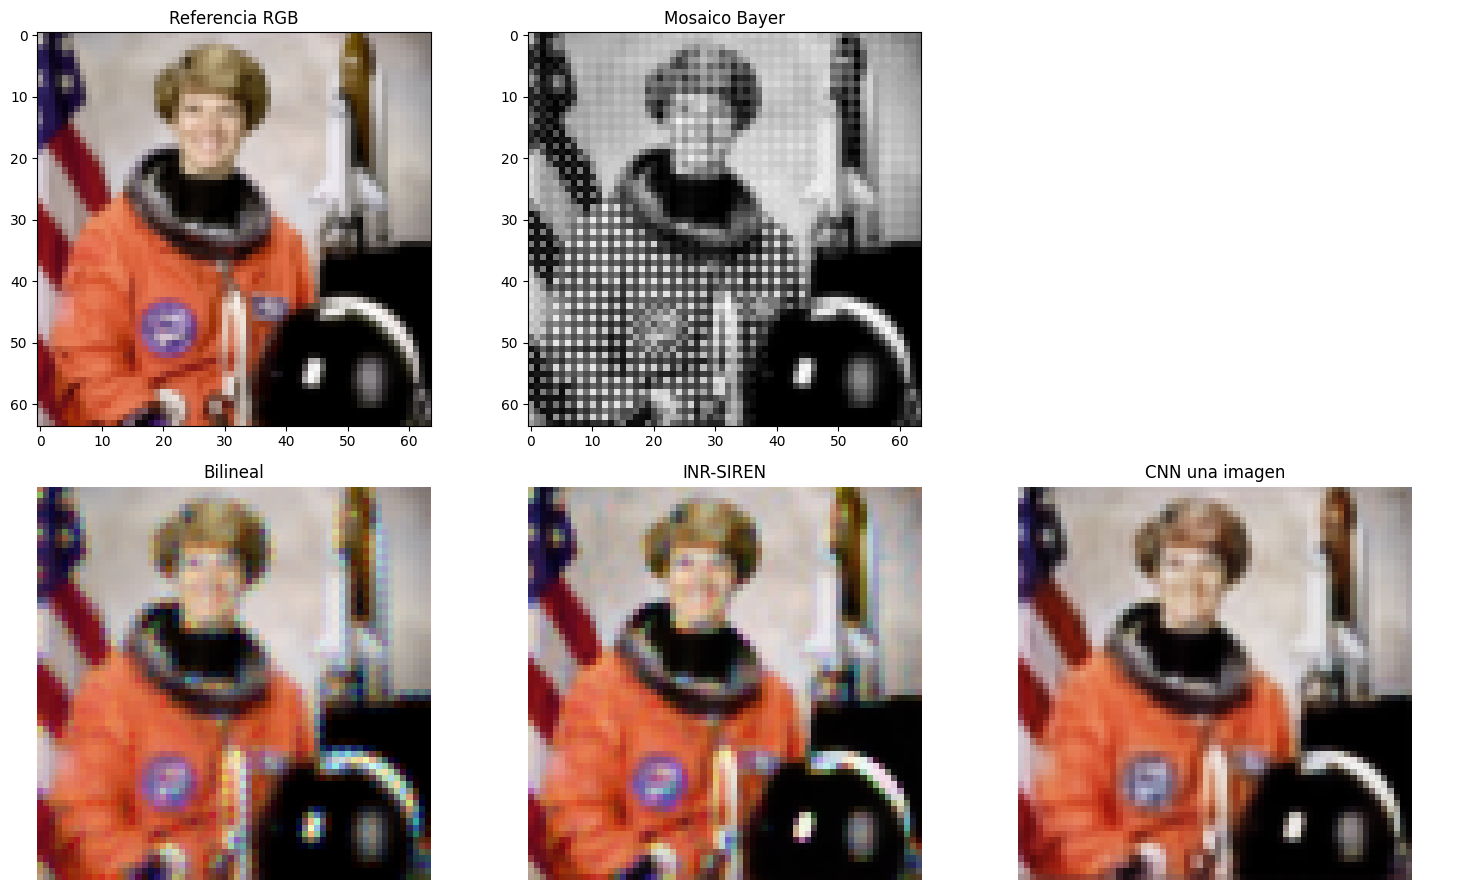

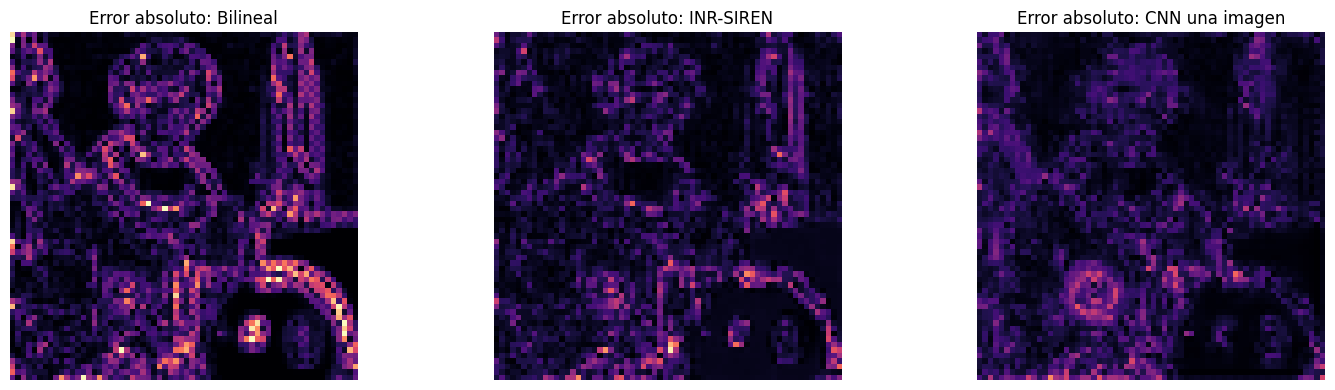

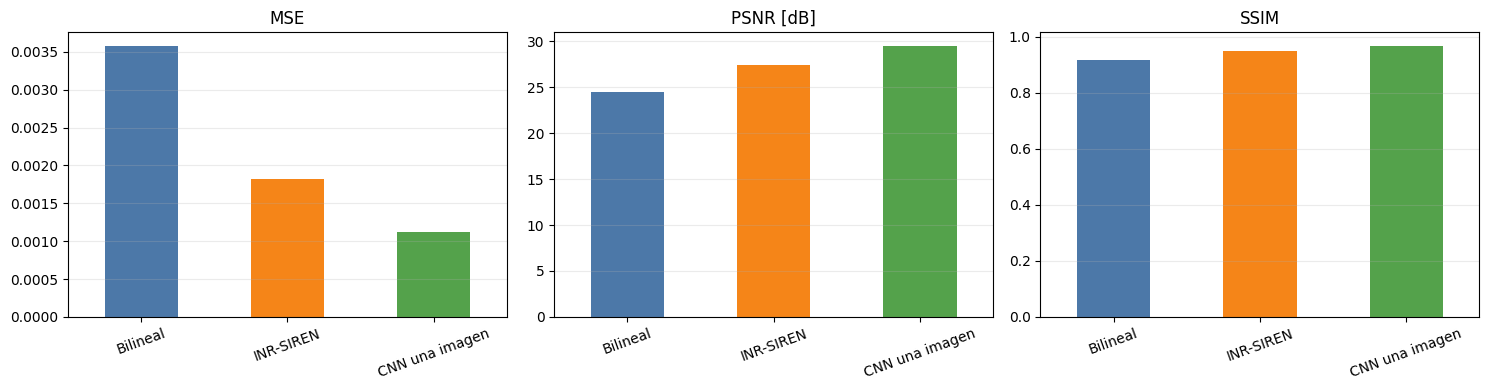

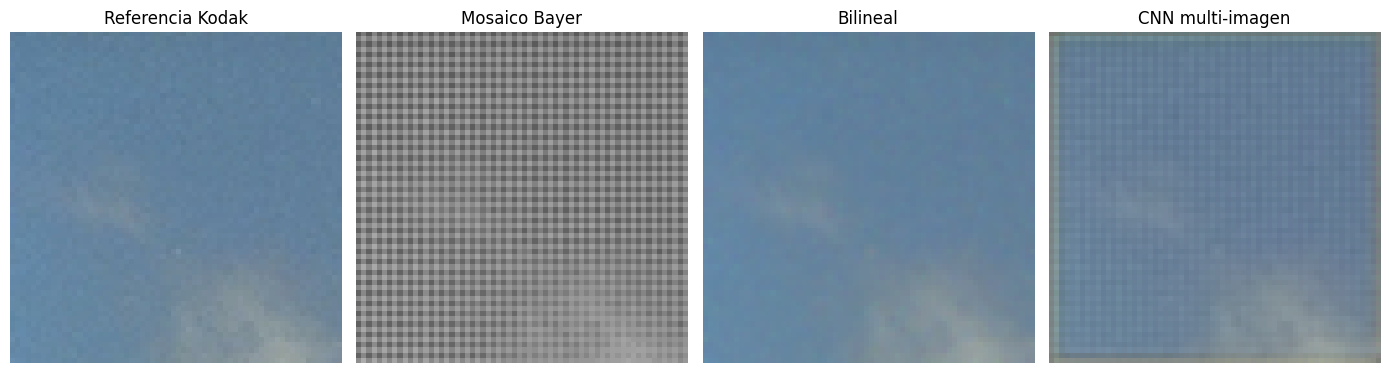

In [10]:
# Visualizacion comparativa
def show_comparison(reference, mosaic, reconstructions, error_scale=5):
    methods = list(reconstructions.keys())
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    axes[0, 0].imshow(reference)
    axes[0, 0].set_title("Referencia RGB")
    axes[0, 1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title("Mosaico Bayer")
    axes[0, 2].axis("off")

    for ax, (method, reconstruction) in zip(axes[1], reconstructions.items()):
        ax.imshow(np.clip(reconstruction, 0, 1))
        ax.set_title(method)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
    for ax, (method, reconstruction) in zip(axes, reconstructions.items()):
        error = np.mean(np.abs(reference - reconstruction), axis=-1)
        ax.imshow(np.clip(error * error_scale, 0, 1), cmap="magma", vmin=0, vmax=1)
        ax.set_title(f"Error absoluto: {method}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

controlled_reconstructions = {
    "Bilineal": I_hat_classic,
    "INR-SIREN": I_hat_inr,
    "CNN una imagen": I_hat_cnn_single,
}
show_comparison(rgb_reference, mosaic, controlled_reconstructions)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#4C78A8", "#F58518", "#54A24B"]
for ax, metric in zip(axes, ["MSE", "PSNR [dB]", "SSIM"]):
    controlled_results_df.plot(kind="bar", x="metodo", y=metric, ax=ax, color=colors, legend=False)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Ejemplo de generalizacion sobre un parche Kodak no usado en entrenamiento.
if "model_cnn_kodak" in globals() and len(test_dataset) > 0:
    test_input, test_target = test_dataset[0]
    with torch.no_grad():
        test_prediction = model_cnn_kodak(test_input[None].to(DEVICE))[0].cpu().numpy()
    test_reference = test_target.numpy().transpose(1, 2, 0)
    test_mosaic = test_input[0].numpy()
    test_reconstruction = test_prediction.transpose(1, 2, 0)
    test_bilinear = demosaic_bilinear(test_mosaic, bayer_masks(*test_mosaic.shape, pattern=bayer_pattern))

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(test_reference)
    axes[0].set_title("Referencia Kodak")
    axes[1].imshow(test_mosaic, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Mosaico Bayer")
    axes[2].imshow(test_bilinear)
    axes[2].set_title("Bilineal")
    axes[3].imshow(np.clip(test_reconstruction, 0, 1))
    axes[3].set_title("CNN multi-imagen")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 14. Analisis

El experimento controlado permite comparar directamente bilineal, SIREN y CNN sobre una imagen con referencia conocida. Sin embargo, la CNN entrenada solo con `astronaut` no debe interpretarse como un metodo generalizable: en ese caso la red puede memorizar la imagen.

La evaluacion relevante para la CNN es el bloque Kodak, porque ahi el modelo se entrena con varias imagenes y se evalua sobre imagenes completas que no participaron en el entrenamiento. Si la CNN multi-imagen obtiene mejor MSE, PSNR o SSIM que la interpolacion bilineal en los parches de prueba, entonces hay evidencia de que aprendio una regla de reconstruccion mas general.

La SIREN cumple un rol distinto. Es una representacion implicita optimizada por imagen desde la medicion Bayer. Por eso es util para estudiar reconstruccion guiada por el modelo fisico de muestreo, pero no se presenta como una red lista para aplicar directamente a nuevas imagenes sin reentrenar.

En la comparacion visual conviene observar bordes, texturas finas, falso color y residuos del patron Bayer. PSNR y SSIM resumen parte del desempeno, pero los mapas de error ayudan a ubicar donde falla cada metodo.


## 15. Conclusiones

La tarea queda organizada en dos niveles. Primero, el experimento con `astronaut` valida la implementacion del mosaico Bayer, la interpolacion bilineal, la SIREN y la CNN. Segundo, Kodak permite entrenar y evaluar la CNN con multiples imagenes, evitando basar la conclusion en una sola muestra.

La interpolacion bilineal funciona como linea base simple y reproducible. La SIREN puede ajustar una imagen especifica usando solo la consistencia con la medicion Bayer, pero requiere optimizacion por cada imagen. La CNN, en cambio, puede aprender de muchas imagenes y luego aplicarse a ejemplos no vistos, por lo que su evaluacion principal debe reportarse sobre el conjunto de prueba Kodak.

La captura RAW/DNG real queda como trabajo pendiente debido a que las imagenes disponibles estan corruptas. Como mejoras futuras se podria repetir el experimento con una captura valida, entrenar por mas epocas, usar aumento de datos, probar patrones Bayer reales detectados desde el DNG y comparar contra algoritmos clasicos mas avanzados de OpenCV o `rawpy`.
